<center><h1>Xie_Zihan_HW4</h1></center>
<br>
<br>

Name: Zihan Xie
<br>
Github Username: SherryXiYe
<br>
USC ID: 6376813348

# 0. Environment Setup

Required Python packages are listed in `requirements.txt`.

To install the dependencies, run:

```bash
pip install -r requirements.txt

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [1]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score

# unpenalized logistic regression on (almost) separable data gives convergence warnings,
# and bending2 has fewer than 5 training instances (sklearn warns in stratified CV); I hide these
warnings.filterwarnings("ignore")
SEED = 42

Get the AReM Data Set

In [2]:
ACTIVITIES = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]
COLS = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]
DATA_DIR = os.path.join("data", "AReM")

def file_no(fname):
    return int(re.search(r"(\d+)", fname).group(1))

def load_instance(path):
    # some files use spaces instead of commas, so split on both and skip the header lines
    rows = []
    with open(path, "r", errors="ignore") as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            try:
                vals = [float(p) for p in re.split(r"[,\s]+", line) if p != ""]
            except ValueError:
                continue
            if len(vals) == 7:
                rows.append(vals[1:])
    return pd.DataFrame(rows, columns=COLS)

### (b) Splitting Data

In [3]:
# test: datasets 1, 2 in bending1/bending2 and datasets 1, 2, 3 in the other folders
def is_test(activity, idx):
    return idx in ((1, 2) if activity in ("bending1", "bending2") else (1, 2, 3))

instances = []
for a in ACTIVITIES:
    folder = os.path.join(DATA_DIR, a)
    for fname in sorted([f for f in os.listdir(folder) if f.startswith("dataset")], key=file_no):
        i = file_no(fname)
        instances.append(dict(activity=a, data=load_instance(os.path.join(folder, fname)),
                              split="test" if is_test(a, i) else "train"))

activity = np.array([d["activity"] for d in instances])
train_mask = np.array([d["split"] == "train" for d in instances])
test_mask = ~train_mask
print("instances:", len(instances), "| train:", train_mask.sum(), "| test:", test_mask.sum())

instances: 88 | train: 69 | test: 19


### (c) Feature Extraction

The feature extraction is the same as in HW3. In HW3 1(c)iv I chose **mean, standard deviation and maximum** as the three most important features. I use these three features in all of Part 2 (also in 2(a)iii and later), so the features stay the same as in the plots of 2(a)i and ii.

In [4]:
def extract_features(arr):
    # arr: (n_timesteps, n_series)
    out = {}
    for j in range(arr.shape[1]):
        x, k = arr[:, j], j + 1
        out[f"min{k}"] = np.min(x)
        out[f"max{k}"] = np.max(x)
        out[f"mean{k}"] = np.mean(x)
        out[f"median{k}"] = np.median(x)
        out[f"std{k}"] = np.std(x, ddof=1)
        out[f"1st_quart{k}"] = np.percentile(x, 25)
        out[f"3rd_quart{k}"] = np.percentile(x, 75)
    return out

features = pd.DataFrame([extract_features(d["data"].values) for d in instances])
SELECTED_TYPES = ["mean", "std", "max"]
print(features.shape)
features.head()

(88, 42)


,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
0,37.25,45.00,40.624792,40.50,1.476967,39.25,42.00,0.0,1.30,0.358604,...,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30
1,38.00,45.67,42.812812,42.50,1.435550,42.00,43.67,0.0,1.22,0.372437,...,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30
2,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,0.426250,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94
3,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,0.696042,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00
4,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,0.535979,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

Bending1 and bending2 are labeled 1 (bending), all other activities 0. `split_features(l)` breaks each of the 6 series of an instance into $l$ consecutive pieces with `np.array_split` (the pieces differ in length by at most one, which also works for the instance with 479 rows) and extracts mean, std and max from every piece. So each instance has $6 \times 3 \times l = 18l$ features, and the number of instances does not change. A feature named `mean5_1` means the mean of piece 1 of series 5. I compute the features for all $l$ once at the beginning; this does not use any labels, so it does not cause any leakage in cross-validation.

In [5]:
y = np.isin(activity, ["bending1", "bending2"]).astype(int)   # 1 = bending, 0 = other
y_train, y_test = y[train_mask], y[test_mask]

def split_features(l):
    # break each series into l pieces and extract mean, std, max from every piece -> 18*l features
    rows = []
    for d in instances:
        row = {}
        for s, piece in enumerate(np.array_split(d["data"].values, l), start=1):
            f = extract_features(piece)
            for k in range(1, 7):
                for t in SELECTED_TYPES:
                    row[f"{t}{k}_{s}"] = f[f"{t}{k}"]
        rows.append(row)
    return pd.DataFrame(rows)

X_l = {l: split_features(l) for l in range(1, 21)}
print("train: bending", y_train.sum(), "other", (y_train == 0).sum())

train: bending 9 other 60


#### i. Plots

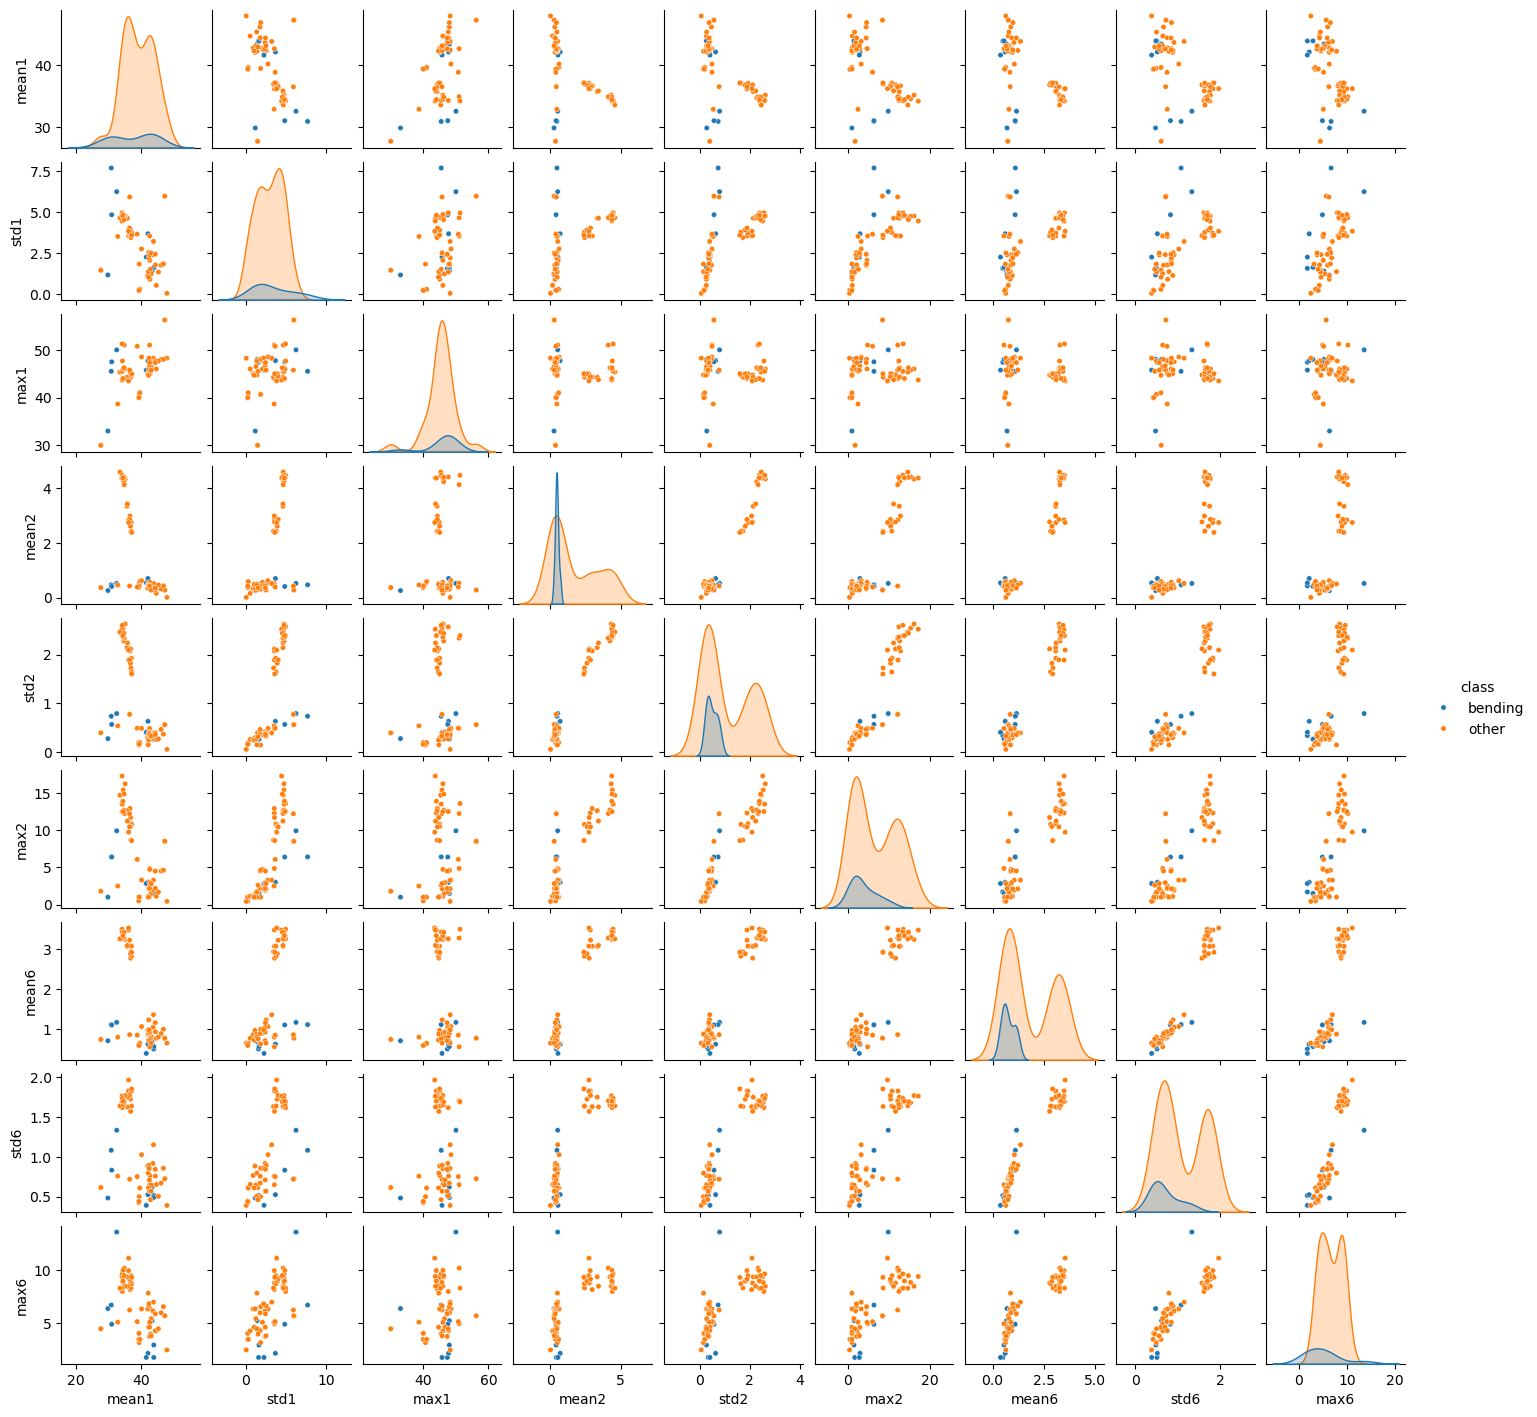

In [6]:
cols = [f"{t}{k}" for k in (1, 2, 6) for t in SELECTED_TYPES]
df = features.loc[train_mask, cols].copy()
df["class"] = np.where(y_train == 1, "bending", "other")
sns.pairplot(df, hue="class", height=1.6, plot_kws={"s": 15})
plt.show()

In series 2 and 6 (the variance series) the "other" activities split into two groups: one with large mean/std/max (cycling and walking) and one with small values. All bending instances are in the small-value group together with lying, sitting and standing, so these features only separate bending from the dynamic activities. In series 1, part of the bending instances have a lower mean (around 30) than most other instances, but the rest overlap with the other activities. Overall no single pair of features separates bending from the other activities well.

#### ii. Splitted Plots

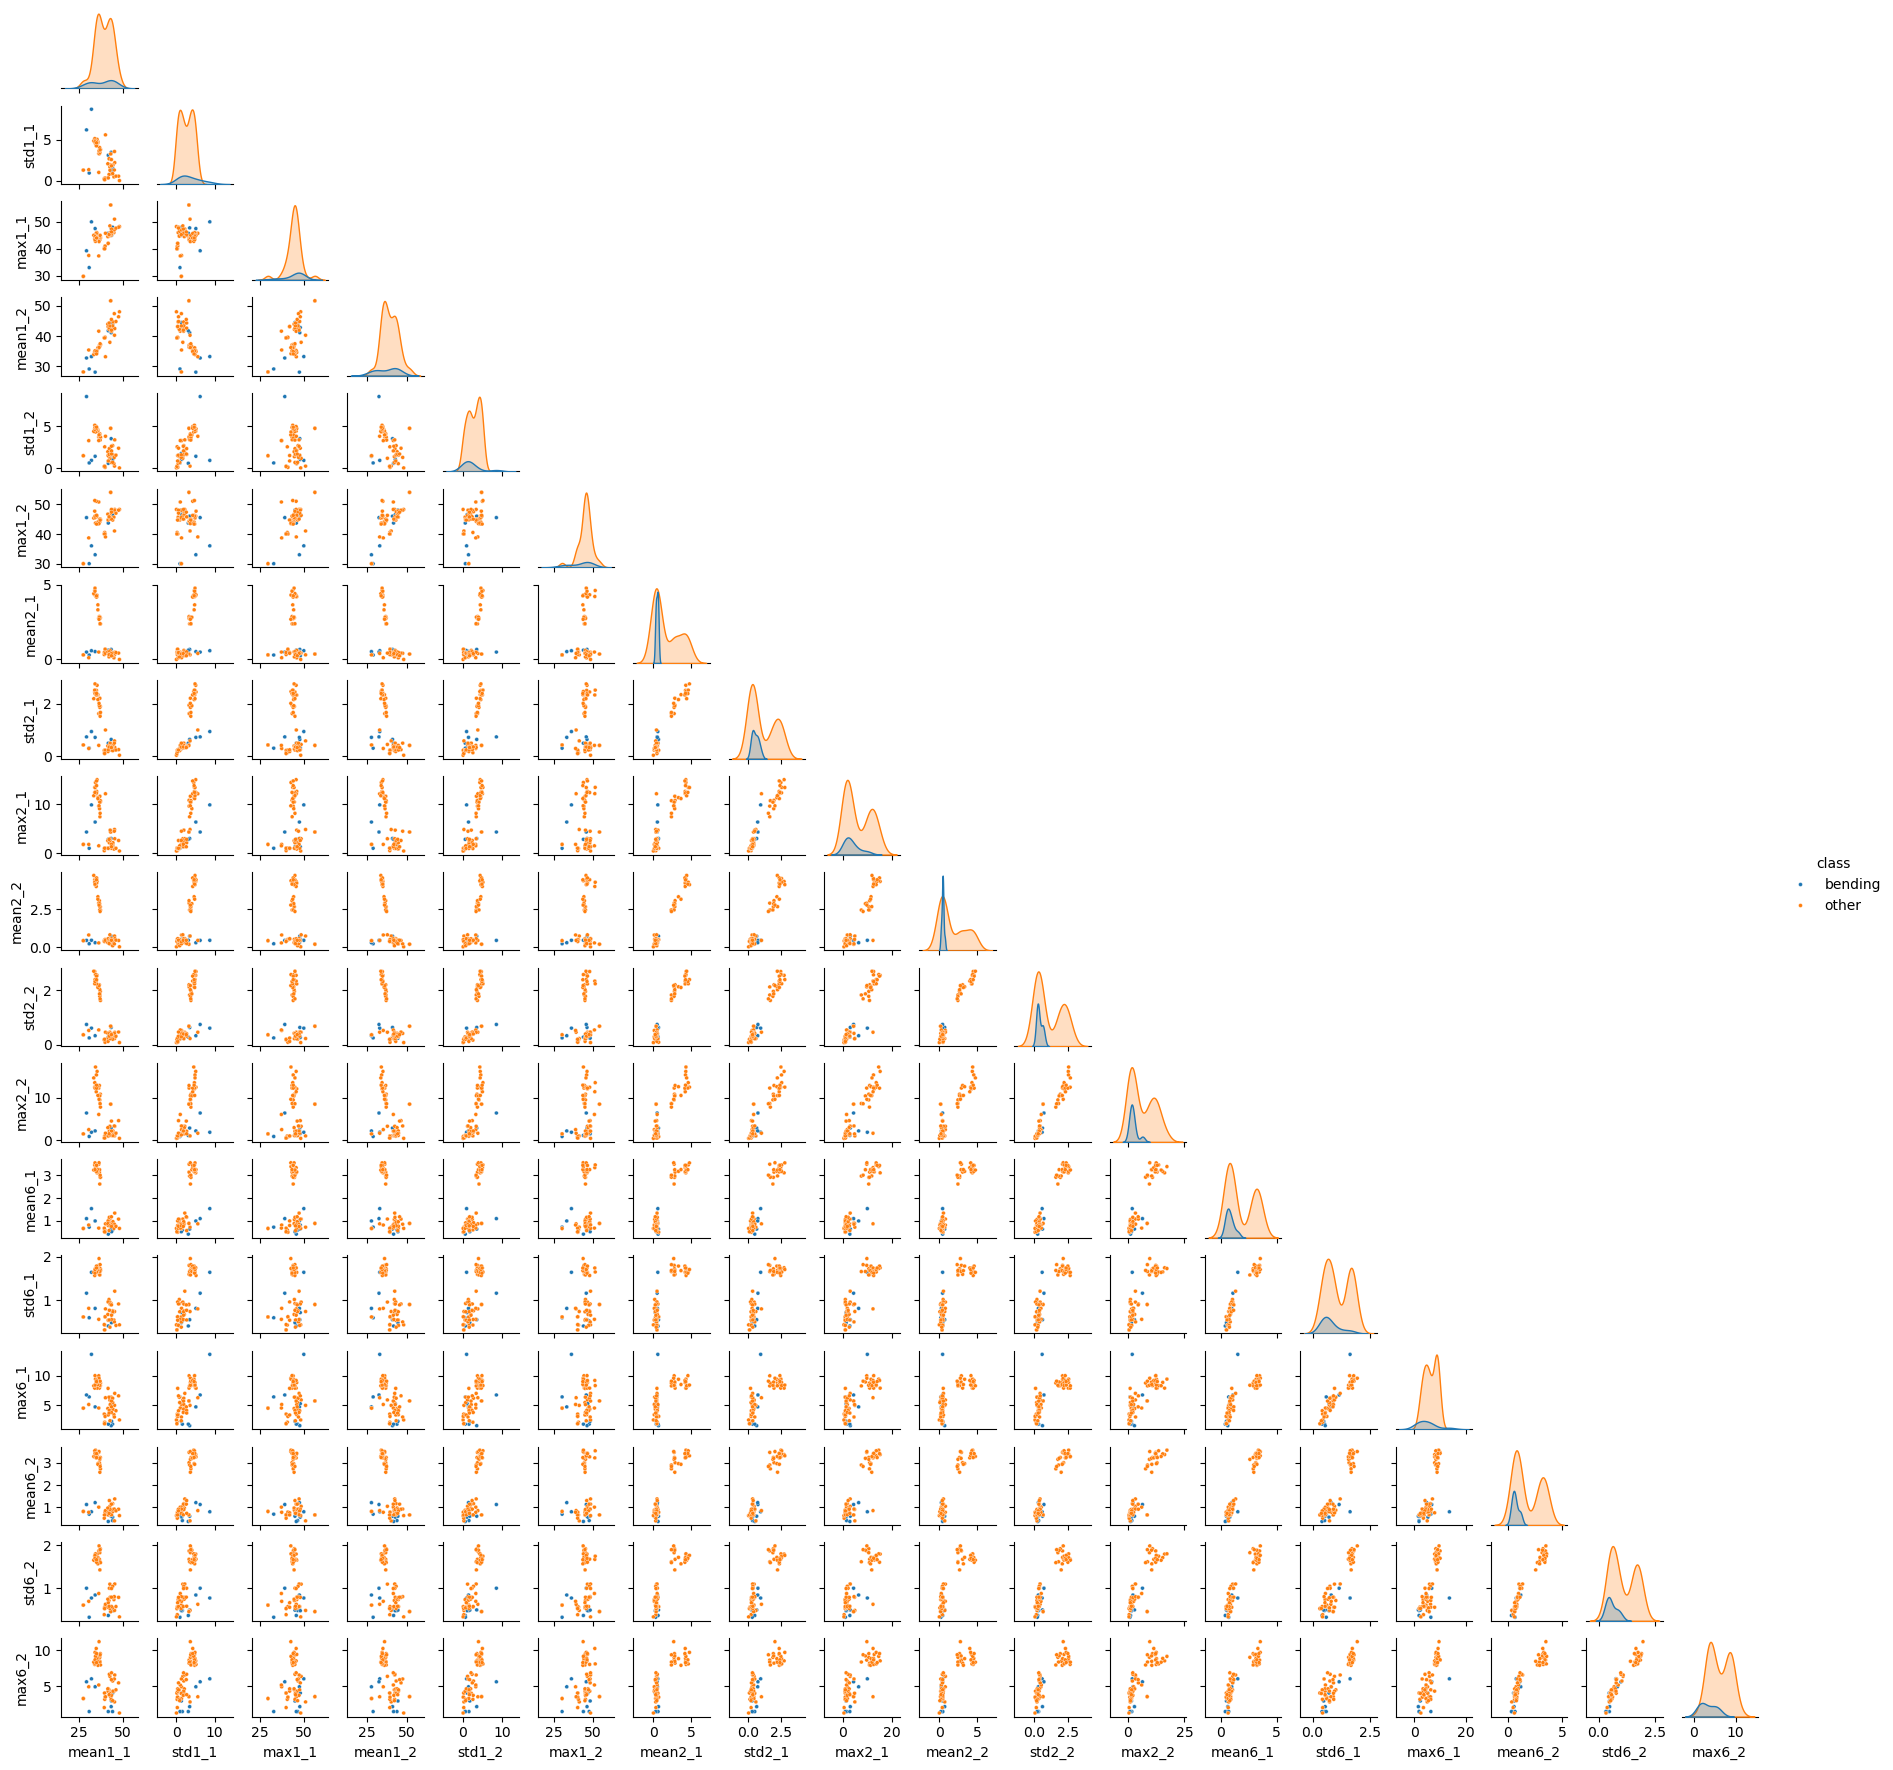

In [7]:
cols2 = [f"{t}{k}_{s}" for k in (1, 2, 6) for s in (1, 2) for t in SELECTED_TYPES]
df2 = X_l[2].loc[train_mask, cols2].copy()
df2["class"] = np.where(y_train == 1, "bending", "other")
sns.pairplot(df2, hue="class", height=1.0, plot_kws={"s": 8}, corner=True)
plt.show()

I don't see a considerable difference from 2(a)i. The features of the first half and the second half of a series are highly correlated (the points are close to a line), since each recording is one activity and the signal does not change much over time. The two halves therefore show the same pattern as the whole series, and the bending instances still overlap with the static activities.

#### iii. Time Series Segments

For feature selection I use RFE (backward selection), which the assignment allows instead of pruning by p-values, and I choose the pair $(l, p)$ by 5-fold cross-validation with $l = 1, \dots, 20$ and $p = 1, \dots, 20$ (for $l = 1$ there are only 18 features, so $p \le 18$). I did not go beyond $p = 20$ because with only 69 training instances (about 55 in each training fold) a logistic regression with many more features would just overfit.

Some details of my setup:

- Logistic regression without penalty (`penalty=None`, same as $C \to \infty$), as required in the footnote. The classes turn out to be almost separable, so I limit `max_iter` to 200 to stop the optimizer early (footnote 5).
- The features are standardized before RFE, because RFE removes the feature with the smallest $|\beta|$, and that only makes sense when the features are on the same scale.
- In each fold I run RFE once down to 1 feature. RFE removes one feature at a time, so the $p$ best features are just the features with `ranking_ <= p`. This gives the RFE result for all $p$ without running RFE 20 times.
- If several $(l, p)$ have the same CV accuracy, I take the one with the fewest features $p$ (and then the smaller $l$), since a simpler model is preferable when the CV cannot tell them apart.

**Wrong way vs. right way.** The wrong way is to run the feature selection on the whole training set first and then do cross-validation only for the logistic regression on the selected features. The features were then chosen using the labels of the validation folds too, so the CV accuracy is too optimistic. The right way is to do the feature selection inside the CV: in each fold, RFE (and the scaling) is fitted only on the 4 training folds, the model is fitted on the selected features, and then it is evaluated on the held-out fold. That is what I do below.

**Stratified CV.** Only 9 of the 69 training instances are bending. Since bending comes first in my data, plain 5-fold CV without shuffling would put all 9 bending instances into the first fold, and even with shuffling some folds can easily have no bending instance. Stratified K-fold CV makes each fold have about the same class proportions as the whole data set, so here every fold has 1 or 2 bending instances. I use `StratifiedKFold` with shuffling and a fixed seed, so all values of $l$ are compared on the same folds.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def logit():
    # no penalty; max_iter is limited because the classes can be separable
    return LogisticRegression(penalty=None, max_iter=200)

results = []
for l in range(1, 21):
    X = X_l[l].values[train_mask]
    p_list = range(1, min(20, X.shape[1]) + 1)
    acc = np.zeros((5, len(p_list)))
    for f, (tr, va) in enumerate(cv.split(X, y_train)):
        scaler = StandardScaler().fit(X[tr])
        X_tr, X_va = scaler.transform(X[tr]), scaler.transform(X[va])
        # run RFE down to 1 feature once; the p best features are the ones with ranking <= p
        rank = RFE(logit(), n_features_to_select=1).fit(X_tr, y_train[tr]).ranking_
        for j, p in enumerate(p_list):
            model = logit().fit(X_tr[:, rank <= p], y_train[tr])
            acc[f, j] = accuracy_score(y_train[va], model.predict(X_va[:, rank <= p]))
    for j, p in enumerate(p_list):
        results.append({"l": l, "p": p, "cv_accuracy": acc[:, j].mean()})

results = pd.DataFrame(results)
best = results.sort_values(["cv_accuracy", "p", "l"], ascending=[False, True, True]).iloc[0]
best_l, best_p, best_cv = int(best.l), int(best.p), best.cv_accuracy
print(results.sort_values(["cv_accuracy", "p", "l"], ascending=[False, True, True]).head(10).to_string(index=False))
print(f"\nbest l = {best_l}, p = {best_p}, CV accuracy = {best_cv:.4f}")

 l  p  cv_accuracy
 3  1     0.985714
13  8     0.985714
10 11     0.985714
10 12     0.985714
10 13     0.985714
10 14     0.985714
10 15     0.985714
10 16     0.985714
10 17     0.985714
10 18     0.985714

best l = 3, p = 1, CV accuracy = 0.9857


The best pair is $l = 3$, $p = 1$ with CV accuracy 0.986, i.e. only 1 of the 69 training instances is misclassified across the 5 folds. Several other pairs, e.g. $(13, 8)$ and $(10, 11)$ to $(10, 18)$, reach the same accuracy. So the differences between the good pairs are only about one instance, and the choice of $(l, p)$ is not very stable; by my tie rule I take the model with one feature. The selected feature is `mean5_1`, the mean of the first third of series 5 (`avg_rss23`).

In [9]:
# refit on the whole training set with the chosen (l, p)
X_train = X_l[best_l].values[train_mask]
X_test = X_l[best_l].values[test_mask]
scaler = StandardScaler().fit(X_train)
Z_train, Z_test = scaler.transform(X_train), scaler.transform(X_test)
sel = RFE(logit(), n_features_to_select=best_p).fit(Z_train, y_train).support_
sel_names = list(X_l[best_l].columns[sel])
model_a = logit().fit(Z_train[:, sel], y_train)
print("selected features:", sel_names)

selected features: ['mean5_1']


#### iv. Confusion Matrix

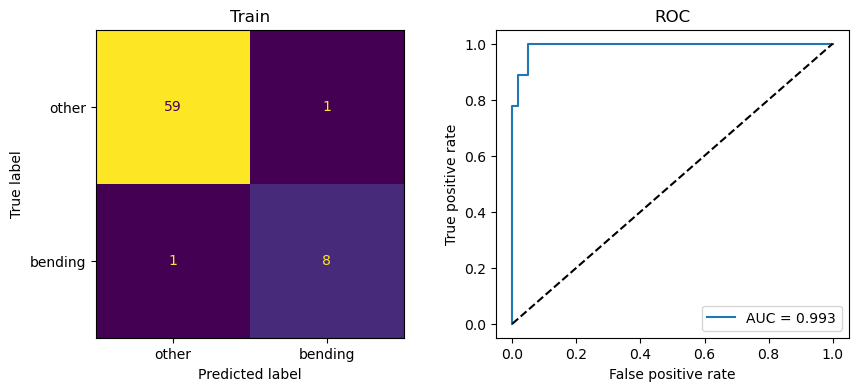

accuracy = 0.9710, AUC = 0.9926


In [10]:
def show_results(y_true, prob, title):
    pred = (prob >= 0.5).astype(int)
    fpr, tpr, _ = roc_curve(y_true, prob)
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ConfusionMatrixDisplay(confusion_matrix(y_true, pred), display_labels=["other", "bending"]).plot(ax=ax[0], colorbar=False)
    ax[0].set_title(title)
    ax[1].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_true, prob):.3f}")
    ax[1].plot([0, 1], [0, 1], "k--")
    ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate")
    ax[1].set_title("ROC"); ax[1].legend()
    plt.show()
    print(f"accuracy = {accuracy_score(y_true, pred):.4f}, AUC = {roc_auc_score(y_true, prob):.4f}")
    return accuracy_score(y_true, pred)

train_acc_a = show_results(y_train, model_a.predict_proba(Z_train[:, sel])[:, 1], "Train")

In [11]:
# beta's and p-values (statsmodels, same standardized features)
logit_sm = sm.Logit(y_train, sm.add_constant(Z_train[:, sel])).fit(disp=0, maxiter=200)
pd.DataFrame({"beta": logit_sm.params, "p-value": logit_sm.pvalues},
             index=["intercept"] + sel_names).round(4)

,beta,p-value
intercept,-10.1722,0.1580
mean5_1,16.9281,0.1914


On the training data the model misclassifies 2 of the 69 instances (1 bending, 1 other), accuracy 0.971 and AUC 0.993. The fitted model (on the standardized feature) is

$$\log\frac{P(\text{bending})}{1-P(\text{bending})} = -10.17 + 16.93 \cdot \texttt{mean5\_1}.$$

The positive coefficient means a larger mean of `avg_rss23` in the first part of the recording makes bending more likely. The p-values are 0.158 for the intercept and 0.191 for `mean5_1`, so they are not significant at the 0.05 level even though this feature separates the classes very well. This is because the two classes are almost separated by this feature, which makes the coefficient and its standard error both large (see vi).

#### v. Test Classifier

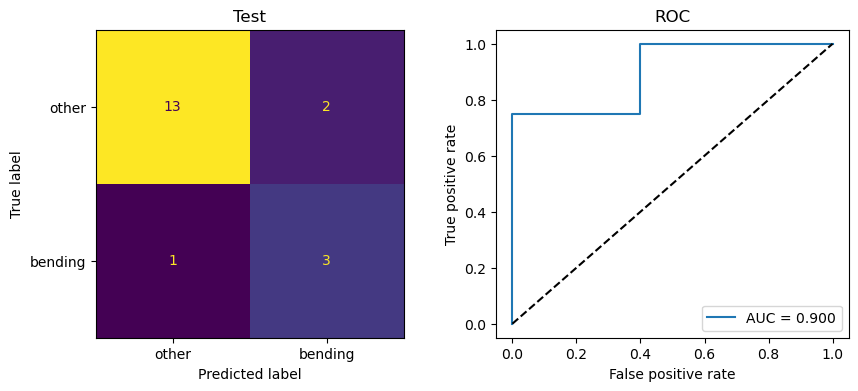

accuracy = 0.8421, AUC = 0.9000
CV accuracy = 0.9857, test accuracy = 0.8421


In [12]:
# test series are broken into the same l pieces; scaler fitted on the training set
test_acc_a = show_results(y_test, model_a.predict_proba(Z_test[:, sel])[:, 1], "Test")
print(f"CV accuracy = {best_cv:.4f}, test accuracy = {test_acc_a:.4f}")

On the test set the accuracy is 0.842 (16 of 19, 2 false positives and 1 false negative) and AUC is 0.90. This is lower than the CV accuracy of 0.986. I think there are three reasons. The test set is very small (19 instances, only 4 bending), so one error already changes the accuracy by about 5%. The CV accuracy is a bit optimistic, because $(l, p)$ was chosen as the best of many pairs on the same folds. And the final model uses only one feature, so it is sensitive to a test recording that looks a bit different from the training recordings.

#### vi. Separation

Yes. The training classes are nearly separated: with only one feature the model already reaches AUC 0.993 with 2 errors, and with more features the training set can be separated perfectly (for example the L1 model in (b) gets 100% training accuracy). When the classes are separable, the maximum likelihood estimate does not exist and the coefficients go to infinity, which is why I had to limit `max_iter`. Even in the final one-feature model the coefficient is large (16.9 on the standardized scale) and the p-values are not significant, which is a sign of this instability.

#### vii. Imbalance

For case-control sampling I keep all 9 bending instances (cases) and randomly sample the same number of other instances (controls), so the sample is balanced (1:1). I fit the logistic regression with the same $l$ and the same selected feature as in (iii). Sampling the controls only changes the intercept, so I adjust it by

$$\hat\beta_0^{*} = \hat\beta_0 + \log\frac{\pi}{1-\pi} - \log\frac{\tilde\pi}{1-\tilde\pi},$$

where $\pi = 9/69$ is the proportion of bending in the training set (my estimate of the population proportion) and $\tilde\pi = 0.5$ the proportion in the case-control sample.

intercept: -30.7503 -> -32.6474


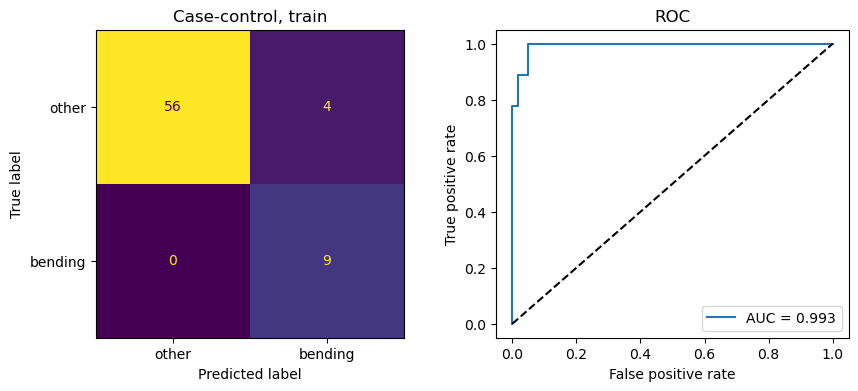

accuracy = 0.9420, AUC = 0.9926


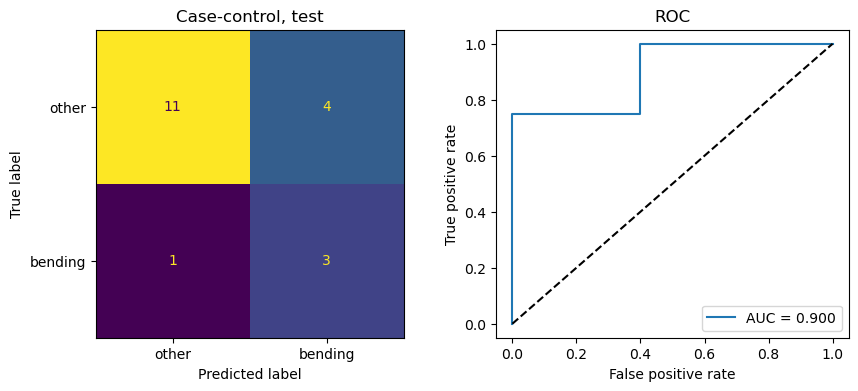

accuracy = 0.7368, AUC = 0.9000


In [13]:
# case-control sampling: keep all 9 bending instances and sample 9 of the 60 other instances
rng = np.random.default_rng(SEED)
cases = np.where(y_train == 1)[0]
controls = rng.choice(np.where(y_train == 0)[0], size=len(cases), replace=False)
idx = np.r_[cases, controls]
model_cc = logit().fit(Z_train[idx][:, sel], y_train[idx])

# adjust the intercept: beta0 + log(pi / (1 - pi)) - log(pi_s / (1 - pi_s))
pi, pi_s = y_train.mean(), y_train[idx].mean()
b0 = model_cc.intercept_[0]
model_cc.intercept_ = model_cc.intercept_ + np.log(pi / (1 - pi)) - np.log(pi_s / (1 - pi_s))
print(f"intercept: {b0:.4f} -> {model_cc.intercept_[0]:.4f}")

show_results(y_train, model_cc.predict_proba(Z_train[:, sel])[:, 1], "Case-control, train")
show_results(y_test, model_cc.predict_proba(Z_test[:, sel])[:, 1], "Case-control, test");

Yes, the classes are imbalanced: 9 bending vs. 60 other in the training set and 4 vs. 15 in the test set. In the confusion matrices the errors concern only a few instances, but with this imbalance always predicting "other" would already give 87% training accuracy, so the accuracy alone looks better than it is.

After the case-control sampling the intercept changed from −30.75 to −32.65. On the training set the model now finds all 9 bending instances but has 4 false positives (accuracy 0.942, AUC 0.993). On the test set it finds 3 of 4 bending instances with 4 false positives (accuracy 0.737, AUC 0.90). The AUC is the same as before, because the intercept only moves the threshold and does not change the ranking of the instances. So here case-control sampling did not improve the classifier: it finds more bending instances on the training set but makes more false positives. With only 18 instances in the sample, the fit also depends a lot on which controls are sampled.

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

Now I use L1-penalized logistic regression instead of RFE. I use the `liblinear` solver as suggested. The features are standardized inside a pipeline, so the scaler is fitted only on the training folds, and standardizing matters here because the L1 penalty treats all coefficients the same. For every $l$, `GridSearchCV` chooses $C = 1/\lambda$ from 9 values between 0.01 and 100 with the same stratified folds as in 2(a)iii. Then I pick the $l$ with the highest CV accuracy (if there is a tie, the smaller $l$).

In [14]:
# for every l, choose C by stratified 5-fold CV (standardization inside the pipeline)
l1_pipe = Pipeline([("scale", StandardScaler()),
                    ("clf", LogisticRegression(penalty="l1", solver="liblinear", max_iter=1000))])
C_grid = {"clf__C": np.logspace(-2, 2, 9)}

l1_res = []
for l in range(1, 21):
    gs = GridSearchCV(l1_pipe, C_grid, cv=cv, scoring="accuracy").fit(X_l[l].values[train_mask], y_train)
    l1_res.append({"l": l, "C": gs.best_params_["clf__C"], "cv_accuracy": gs.best_score_})
l1_res = pd.DataFrame(l1_res)
print(l1_res.round(4).to_string(index=False))

b = l1_res.sort_values(["cv_accuracy", "l"], ascending=[False, True]).iloc[0]
l1_l, l1_C, l1_cv = int(b.l), b.C, b.cv_accuracy
print(f"\nbest l = {l1_l}, C = {l1_C:.4g}, CV accuracy = {l1_cv:.4f}")

 l      C  cv_accuracy
 1 3.1623       0.9714
 2 0.3162       0.9571
 3 0.3162       0.9714
 4 0.3162       0.9571
 5 1.0000       0.9418
 6 0.3162       0.9571
 7 0.3162       0.9418
 8 0.3162       0.9286
 9 0.3162       0.9132
10 3.1623       0.9571
11 1.0000       0.9571
12 1.0000       0.9857
13 1.0000       0.9571
14 0.3162       0.9714
15 0.3162       0.9571
16 1.0000       0.9429
17 1.0000       0.9571
18 1.0000       0.9857
19 1.0000       0.9857
20 1.0000       0.9857

best l = 12, C = 1, CV accuracy = 0.9857


non-zero coefficients: 5 of 216


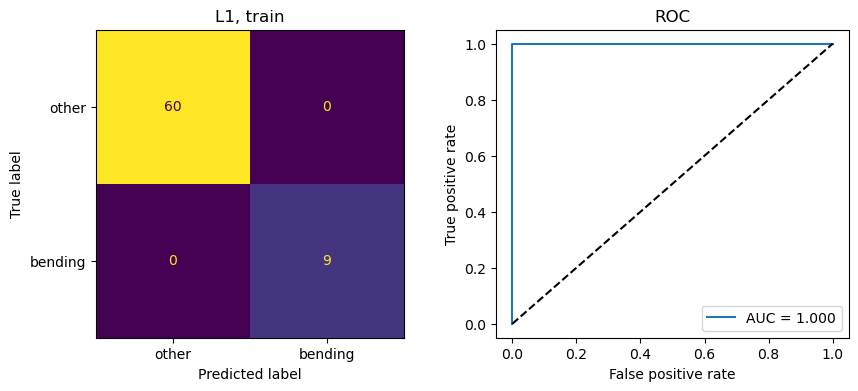

accuracy = 1.0000, AUC = 1.0000


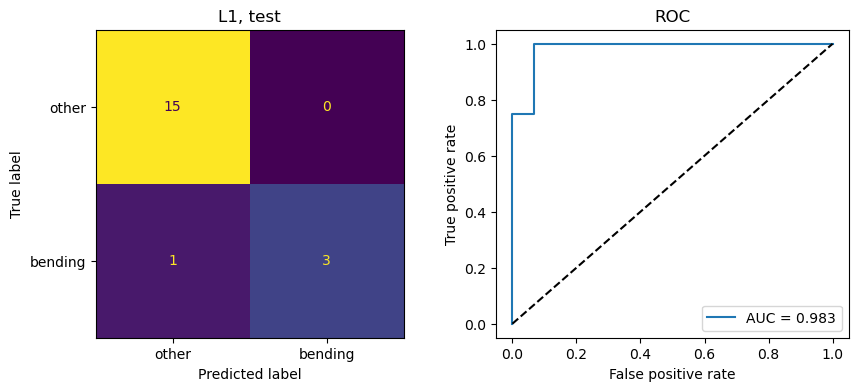

accuracy = 0.9474, AUC = 0.9833


In [15]:
model_b = l1_pipe.set_params(clf__C=l1_C).fit(X_l[l1_l].values[train_mask], y_train)
coef = pd.Series(model_b.named_steps["clf"].coef_[0], index=X_l[l1_l].columns)
print("non-zero coefficients:", (coef != 0).sum(), "of", len(coef))

show_results(y_train, model_b.predict_proba(X_l[l1_l].values[train_mask])[:, 1], "L1, train")
test_acc_b = show_results(y_test, model_b.predict_proba(X_l[l1_l].values[test_mask])[:, 1], "L1, test")

The best model uses $l = 12$ and $C = 1$ with CV accuracy 0.986 ($l = 18, 19, 20$ give the same accuracy). Only 5 of the 216 coefficients are non-zero, so the penalty did most of the feature selection. The model classifies the training set perfectly. On the test set it misclassifies one bending instance as other (accuracy 0.947, AUC 0.983) and has no false positives.

#### ii. Comparison

The CV accuracies are the same (0.986 for both). On the test set, L1-penalized logistic regression is better: accuracy 0.947 vs. 0.842 and AUC 0.983 vs. 0.90. With only 19 test instances this is a difference of 2 instances, so it is not a big difference, but L1 is at least as good here and it is also more stable, since the penalty keeps the coefficients finite even when the classes are separable.

L1-penalized regression is also easier to implement. The variable selection is done by the penalty itself, so I only need to tune $C$ with `GridSearchCV` for each $l$. With p-values/RFE I had to write the CV loop myself to do the feature selection inside each fold, and the unpenalized model has the separation problem.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

Now I classify all 7 activities. I keep bending1 and bending2 as two classes, since they are two different folders (two different bending positions). The model is L1-penalized multinomial logistic regression with the `saga` solver (it supports the L1 penalty for the multinomial loss; `liblinear` cannot do multinomial). As in 2(b)i, the features are standardized inside the pipeline and $l$ and $C$ are chosen by stratified 5-fold CV, with $C$ from 7 values between 0.1 and 100. bending2 has only 4 training instances, so one fold has no bending2 instance; I still use 5 folds as in the other parts.

In [16]:
y_train_m, y_test_m = activity[train_mask], activity[test_mask]

mn_pipe = Pipeline([("scale", StandardScaler()),
                    ("clf", LogisticRegression(penalty="l1", solver="saga", max_iter=2000, tol=1e-3))])
mn_grid = {"clf__C": np.logspace(-1, 2, 7)}

mn_res = []
for l in range(1, 21):
    gs = GridSearchCV(mn_pipe, mn_grid, cv=cv, scoring="accuracy", n_jobs=-1).fit(X_l[l].values[train_mask], y_train_m)
    mn_res.append({"l": l, "C": gs.best_params_["clf__C"], "cv_accuracy": gs.best_score_})
mn_res = pd.DataFrame(mn_res)
print(mn_res.round(4).to_string(index=False))

b = mn_res.sort_values(["cv_accuracy", "l"], ascending=[False, True]).iloc[0]
mn_l, mn_C, mn_cv = int(b.l), b.C, b.cv_accuracy
print(f"\nbest l = {mn_l}, C = {mn_C:.4g}, CV accuracy = {mn_cv:.4f}")

 l        C  cv_accuracy
 1   1.0000       0.8989
 2 100.0000       0.8560
 3  31.6228       0.8275
 4   3.1623       0.8275
 5  10.0000       0.8571
 6  10.0000       0.8857
 7  31.6228       0.8846
 8 100.0000       0.8132
 9  31.6228       0.8571
10   3.1623       0.7989
11 100.0000       0.8857
12 100.0000       0.8714
13  31.6228       0.8286
14 100.0000       0.8275
15  31.6228       0.8560
16   1.0000       0.7846
17   1.0000       0.8286
18  31.6228       0.8418
19 100.0000       0.8418
20  31.6228       0.8571

best l = 1, C = 1, CV accuracy = 0.8989


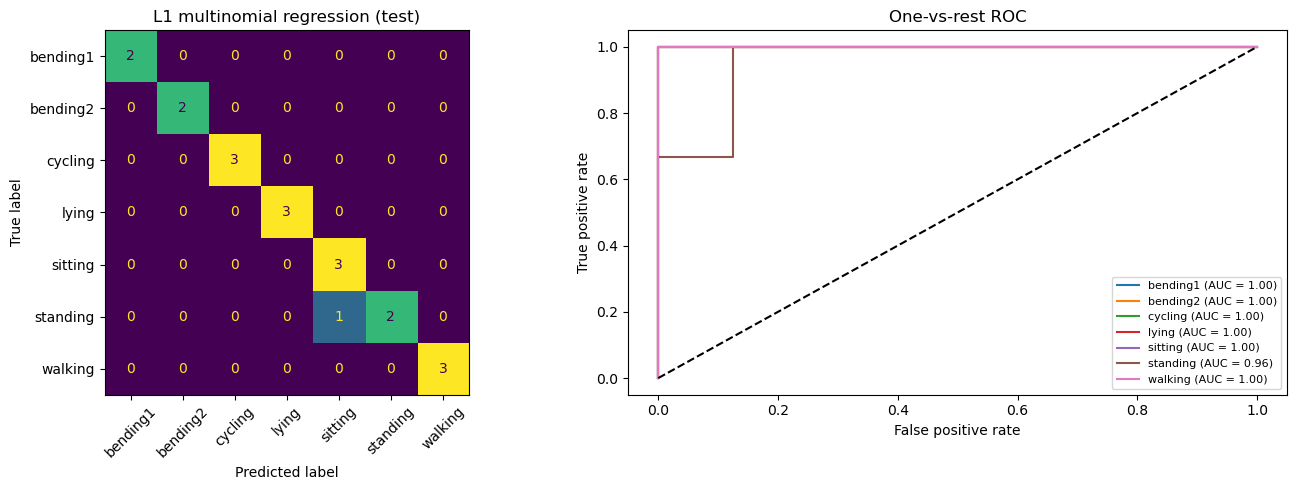

test error = 0.0526


In [17]:
def show_multiclass(model, l, title):
    X_te = X_l[l].values[test_mask]
    pred, prob = model.predict(X_te), model.predict_proba(X_te)
    classes = model.classes_
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    ConfusionMatrixDisplay(confusion_matrix(y_test_m, pred, labels=classes), display_labels=classes).plot(
        ax=ax[0], colorbar=False, xticks_rotation=45)
    ax[0].set_title(title)
    Y = label_binarize(y_test_m, classes=classes)
    for k, c in enumerate(classes):
        fpr, tpr, _ = roc_curve(Y[:, k], prob[:, k])
        ax[1].plot(fpr, tpr, label=f"{c} (AUC = {roc_auc_score(Y[:, k], prob[:, k]):.2f})")
    ax[1].plot([0, 1], [0, 1], "k--")
    ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate")
    ax[1].set_title("One-vs-rest ROC"); ax[1].legend(fontsize=8)
    plt.tight_layout(); plt.show()
    err = 1 - accuracy_score(y_test_m, pred)
    print(f"test error = {err:.4f}")
    return err

model_mn = mn_pipe.set_params(clf__C=mn_C).fit(X_l[mn_l].values[train_mask], y_train_m)
err_mn = show_multiclass(model_mn, mn_l, "L1 multinomial regression (test)")

The best model uses $l = 1$ and $C = 1$ (CV accuracy 0.899). Splitting the series does not help in the multiclass case: no larger $l$ gives a higher CV accuracy than $l = 1$, probably because there are only 69 instances for 7 classes and more features just add noise. The test error is 0.053: only 1 of the 19 test instances is wrong (a standing instance predicted as sitting).

For multiclass problems the confusion matrix is a $K \times K$ table where entry $(i, j)$ is the number of instances of true class $i$ predicted as class $j$. ROC curves are defined for two classes, so for $K$ classes I use one-vs-rest: for each class $k$ I treat class $k$ as positive and all other classes as negative, using $\hat P(Y = k \mid x)$ as the score. This gives one ROC curve and one AUC for each class. Here all classes have AUC 1.00 except standing (0.96).

#### ii. Naive Bayes

I choose $l$ for each Naive Bayes model by the same stratified 5-fold CV. Gaussian NB does not need standardization, since it estimates a separate mean and variance for each feature. Multinomial NB needs non-negative features; all my features (means, standard deviations and maxima of RSS values) are already non-negative, so I use them directly. I keep the default smoothing parameters and only tune $l$.

In [18]:
# choose l by the same 5-fold CV; all features are non-negative, so they can be used directly in MultinomialNB
nb_res = []
for name, nb in [("Gaussian", GaussianNB()), ("Multinomial", MultinomialNB())]:
    for l in range(1, 21):
        scores = []
        for tr, va in cv.split(X_l[l].values[train_mask], y_train_m):
            X = X_l[l].values[train_mask]
            scores.append(accuracy_score(y_train_m[va], nb.fit(X[tr], y_train_m[tr]).predict(X[va])))
        nb_res.append({"model": name, "l": l, "cv_accuracy": np.mean(scores)})
nb_res = pd.DataFrame(nb_res)
print(nb_res.pivot(index="l", columns="model", values="cv_accuracy").round(4).T.to_string())

nb_best = {}
for name in ["Gaussian", "Multinomial"]:
    r = nb_res[nb_res.model == name].sort_values(["cv_accuracy", "l"], ascending=[False, True]).iloc[0]
    nb_best[name] = (int(r.l), r.cv_accuracy)
    print(f"{name} NB: best l = {int(r.l)}, CV accuracy = {r.cv_accuracy:.4f}")

l                1       2       3       4       5       6       7       8       9       10      11      12      13      14      15      16      17      18      19      20
model                                                                                                                                                                      
Gaussian     0.8857  0.8560  0.8418  0.8560  0.8275  0.8560  0.8132  0.7989  0.7692  0.7549  0.7846  0.7989  0.6967  0.7418  0.7396  0.7407  0.7692  0.7099  0.7407  0.7692
Multinomial  0.8560  0.8703  0.8418  0.8571  0.8429  0.8286  0.8286  0.8560  0.8286  0.7989  0.8714  0.8429  0.7846  0.8286  0.8275  0.7692  0.7846  0.7989  0.7989  0.7846
Gaussian NB: best l = 1, CV accuracy = 0.8857
Multinomial NB: best l = 11, CV accuracy = 0.8714


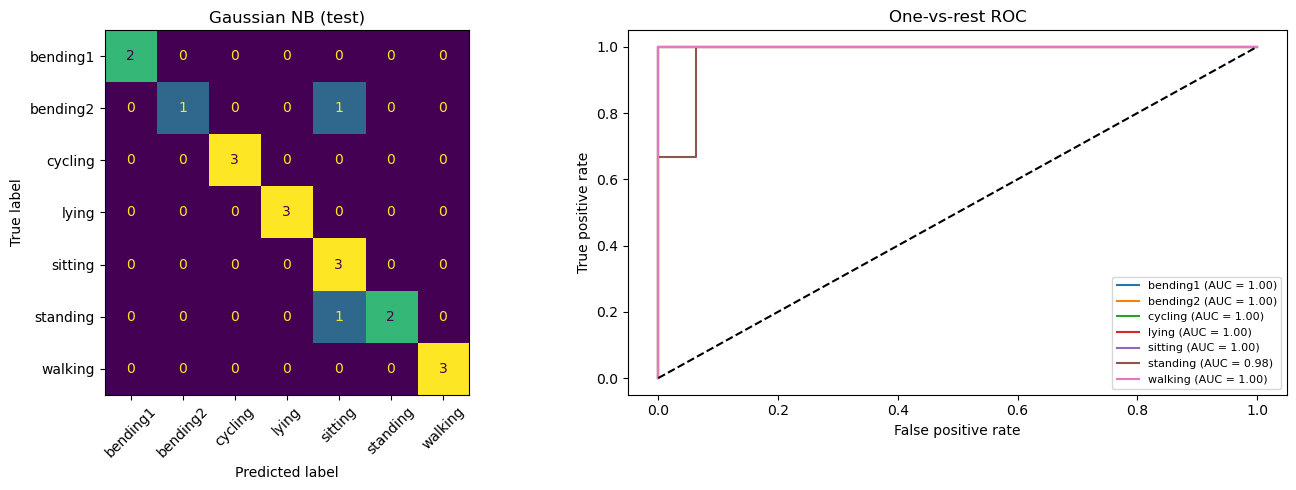

test error = 0.1053


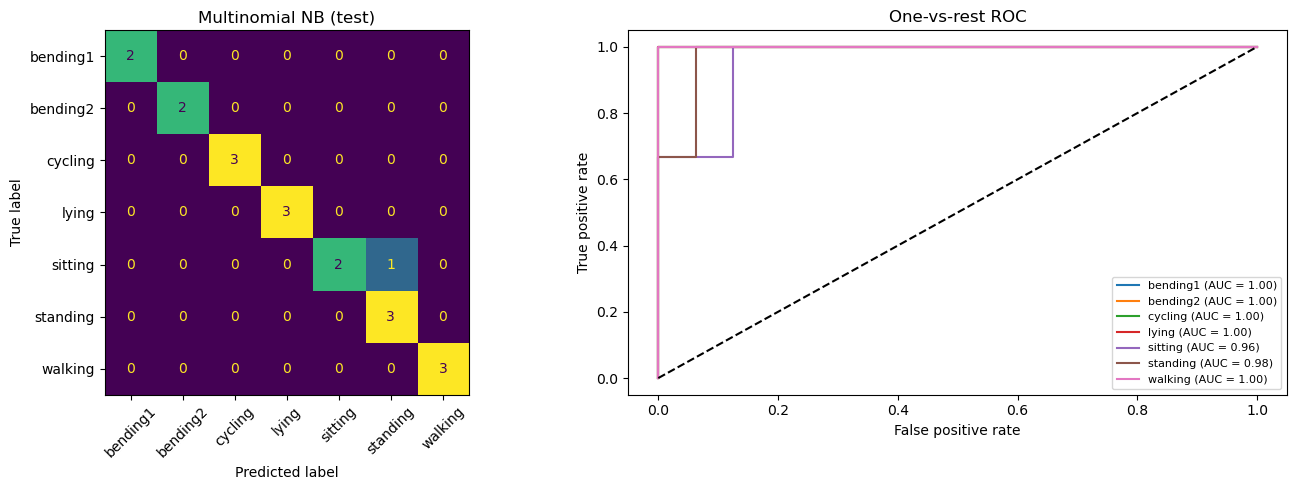

test error = 0.0526


In [19]:
gnb_l, mnb_l = nb_best["Gaussian"][0], nb_best["Multinomial"][0]
gnb = GaussianNB().fit(X_l[gnb_l].values[train_mask], y_train_m)
mnb = MultinomialNB().fit(X_l[mnb_l].values[train_mask], y_train_m)
err_gnb = show_multiclass(gnb, gnb_l, "Gaussian NB (test)")
err_mnb = show_multiclass(mnb, mnb_l, "Multinomial NB (test)")

Gaussian NB chooses $l = 1$ (CV accuracy 0.886) and has test error 0.105 (one bending2 and one standing instance predicted as sitting). Multinomial NB chooses $l = 11$ (CV accuracy 0.871) and has test error 0.053 (one sitting instance predicted as standing). On the test set Multinomial NB is better, but its CV accuracy is a bit lower, and the difference between them is only one test instance. The Gaussian model fits continuous features more naturally, while the multinomial model is designed for count data, so I would not say one is clearly better than the other here.

#### iii. Comparison

In [20]:
pd.DataFrame({"l": [mn_l, gnb_l, mnb_l],
              "CV accuracy": [mn_cv, nb_best["Gaussian"][1], nb_best["Multinomial"][1]],
              "test error": [err_mn, err_gnb, err_mnb]},
             index=["L1 multinomial", "Gaussian NB", "Multinomial NB"]).round(4)

,l,CV accuracy,test error
L1 multinomial,1,0.8989,0.0526
Gaussian NB,1,0.8857,0.1053
Multinomial NB,11,0.8714,0.0526


L1-penalized multinomial logistic regression is the best method here. It has the highest CV accuracy (0.899) and the lowest test error (0.053, tied with Multinomial NB). Naive Bayes assumes the features are independent given the class, but the features here are strongly correlated (e.g. mean and max of the same series), while logistic regression does not need this assumption. In all three models most errors are between sitting and standing, which are both static upright postures and give similar signals. Since the test set has only 19 instances, the test errors differ by at most one instance, so I also rely on the CV accuracy for the comparison.

## 3. ISLR 4.8.3

With $X \mid Y=k \sim N(\mu_k, \sigma_k^2)$ and prior $\pi_k$, the Bayes classifier assigns $x$ to the class with the largest

$$p_k(x) = \frac{\pi_k \frac{1}{\sqrt{2\pi}\sigma_k} \exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right)}{\sum_{l=1}^K \pi_l \frac{1}{\sqrt{2\pi}\sigma_l} \exp\left(-\frac{(x-\mu_l)^2}{2\sigma_l^2}\right)}.$$

The denominator is the same for every $k$, so taking the log of the numerator and dropping the constant $-\frac{1}{2}\log 2\pi$, this is the same as maximizing

$$\delta_k(x) = -\frac{x^2}{2\sigma_k^2} + \frac{\mu_k}{\sigma_k^2}x - \frac{\mu_k^2}{2\sigma_k^2} - \log\sigma_k + \log\pi_k.$$

In LDA all $\sigma_k$ are equal, so the $x^2$ term is the same for every class and can be dropped, which gives a linear discriminant. Here the coefficient of $x^2$ is $-\frac{1}{2\sigma_k^2}$, which is different for each class, so it does not cancel. The boundary between classes $k$ and $l$ is $\delta_k(x) = \delta_l(x)$:

$$\left(\frac{1}{2\sigma_l^2} - \frac{1}{2\sigma_k^2}\right)x^2 + \left(\frac{\mu_k}{\sigma_k^2} - \frac{\mu_l}{\sigma_l^2}\right)x + \left(\frac{\mu_l^2}{2\sigma_l^2} - \frac{\mu_k^2}{2\sigma_k^2} + \log\frac{\sigma_l}{\sigma_k} + \log\frac{\pi_k}{\pi_l}\right) = 0,$$

and the coefficient of $x^2$ is not 0 when $\sigma_k \neq \sigma_l$. So the Bayes classifier is not linear, it is quadratic in $x$.

## 4. ISLR 4.8.7

$\pi_{Yes} = 0.8$, $\pi_{No} = 0.2$, $\mu_{Yes} = 10$, $\mu_{No} = 0$, $\sigma^2 = 36$. By Bayes' theorem (the factor $\frac{1}{\sqrt{2\pi\sigma^2}}$ cancels):

$$P(Yes \mid X=4) = \frac{0.8\, e^{-(4-10)^2/72}}{0.8\, e^{-(4-10)^2/72} + 0.2\, e^{-(4-0)^2/72}} = \frac{0.8 e^{-0.5}}{0.8 e^{-0.5} + 0.2 e^{-0.222}} = \frac{0.4852}{0.4852 + 0.1601} \approx 0.752$$

So the probability that the company issues a dividend is about 75.2%.

## 5.1. Extra Practice ISLR 4.8.4

## 5.2. Extra Practice ISLR 4.8.9